## Slope Analysis (UAV Lidar DEM)

### Computes slope in **degrees** (or percent) using a 3x3 Horn gradient.

#### CRS: EPSG:25832.

In [60]:
# User Configuration

DEM_PATH    = "data/dem_2026.tif"         # input lidar DEM
OUTPUT_PATH = "output/slope_2026.tif"       # output raster
UNITS       = "degrees"               # "degrees" or "percent"

# 5-category classification
# Class boundaries (upper edges) in the chosen UNITS. Must be 4 values ->
# produces 5 classes:  <b1 | b1-b2 | b2-b3 | b3-b4 | >b4
# Defaults (degrees): Flat / Gentle / Moderate / Steep / Very steep

CLASS_BREAKS  = [7, 15, 25, 38]                     # 4 breaks -> 5 classes
CLASS_LABELS  = ["Flat (0-7)", "Gentle (7-15)",
                 "Moderate (15-25)", "Steep (25-38)",
                 "Very steep (>38)"]
CLASS_COLORS  = ["#440154", "#3B528C", "#21918D",
                 "#5DC963", "#FEE825"]             # 5 colors

In [61]:
# Import required Libraries and read DEM file

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from dem_utils import read_dem, write_raster


dem, profile, (res_x, res_y) = read_dem(DEM_PATH)
print(f"DEM shape: {dem.shape}, pixel size: {res_x} x {res_y} m")

DEM shape: (1546, 1322), pixel size: 0.25 x 0.25 m


In [62]:
# Compute slope

def compute_slope(dem, res_x, res_y, units="degrees"):
    """Horn's method: slope from 3x3 neighborhood gradients."""
    # np.gradient returns d/drow, d/dcol; scale by pixel size
    dzdy, dzdx = np.gradient(dem, res_y, res_x)
    slope_rad = np.arctan(np.sqrt(dzdx**2 + dzdy**2))
    if units == "degrees":
        return np.degrees(slope_rad)
    elif units == "percent":
        return np.tan(slope_rad) * 100.0
    raise ValueError("units must be 'degrees' or 'percent'")


slope = compute_slope(dem, res_x, res_y, UNITS)

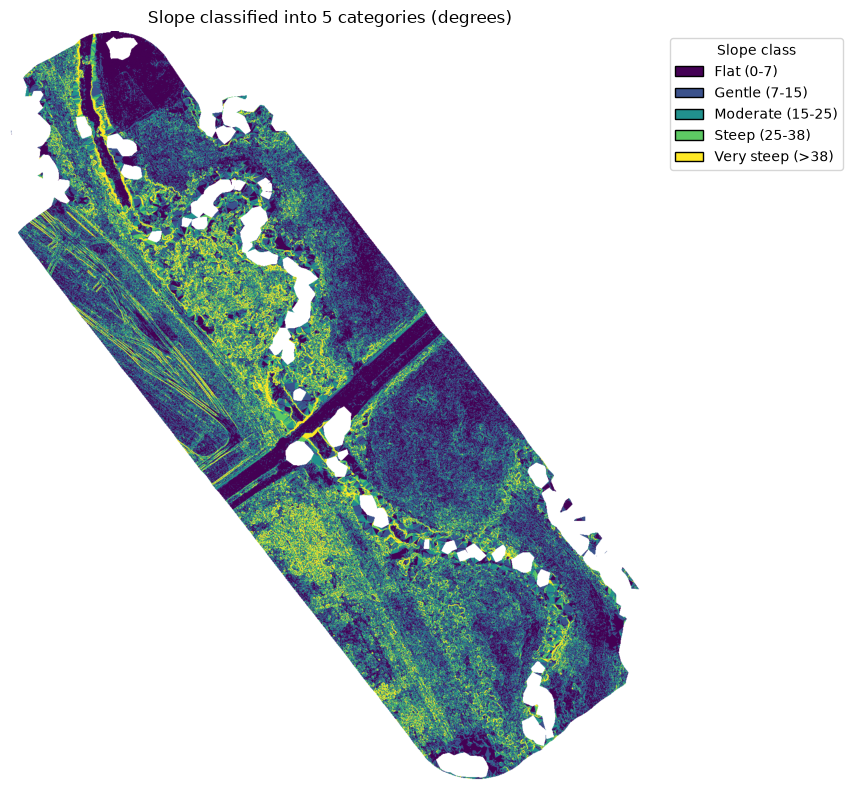

In [63]:
# Classify and visulaize slope into 5 categories

def classify_slope(slope, breaks):
    """Return integer class raster (1..5) from 4 break values.
    NaN cells stay NaN."""
    if len(breaks) != 4:
        raise ValueError("CLASS_BREAKS must contain exactly 4 values (=> 5 classes).")
    # np.digitize: class indices 0..4 -> shift to 1..5
    classes = np.digitize(slope, bins=breaks, right=False).astype("float64") + 1
    classes[np.isnan(slope)] = np.nan
    return classes

slope_class = classify_slope(slope, CLASS_BREAKS)


# Visualise the classified slope

cmap = ListedColormap(CLASS_COLORS)
# Boundaries at 0.5..5.5 so each integer class maps to one color
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(slope_class, cmap=cmap, norm=norm)
ax.set_title(f"Slope classified into 5 categories ({UNITS})")
ax.axis("off")

# Legend with class labels
legend_handles = [Patch(facecolor=c, edgecolor="k", label=l)
                  for c, l in zip(CLASS_COLORS, CLASS_LABELS)]
ax.legend(handles=legend_handles, title="Slope class",
          bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


In [64]:
# Calculate class area statistics

valid = slope_class[~np.isnan(slope_class)]
pixel_area = abs(res_x * res_y)
print("=== SLOPE CLASS AREAS ===")
for i, label in enumerate(CLASS_LABELS, start=1):
    n = int(np.sum(valid == i))
    area = n * pixel_area
    pct = 100.0 * n / valid.size if valid.size else 0.0
    print(f"{label:<20}: {n:>10,} cells | {area:>14,.1f} m^2 | {pct:5.1f}%")

=== SLOPE CLASS AREAS ===
Flat (0-7)          :    215,769 cells |       13,485.6 m^2 |  26.2%
Gentle (7-15)       :    261,265 cells |       16,329.1 m^2 |  31.7%
Moderate (15-25)    :    184,783 cells |       11,548.9 m^2 |  22.5%
Steep (25-38)       :    109,443 cells |        6,840.2 m^2 |  13.3%
Very steep (>38)    :     51,656 cells |        3,228.5 m^2 |   6.3%


In [65]:
# Save slope raster

write_raster(OUTPUT_PATH, slope, profile)

Saved: output/slope_2026.tif
